# Sujet 16 — Visual Anomaly Detection : synthèse
**Objectif :** apprendre l'apparence **normale** d'un produit à partir d'images **saines uniquement**, puis **détecter et localiser** tout écart majeur (fissure, rayure, contamination…).
**Données :** MVTec AD, catégories `bottle` (objet stable), `hazelnut` (objet naturel qui tourne), `carpet` (texture).

```
image brute
  │ 1. PRÉTRAITEMENT    gris 256×256 · filtre médian 3×3 · normalisation de l'éclairage · ALIGNEMENT (centroïde + rotation)
  │ 2. CARACTÉRISTIQUES zones qui se chevauchent : histogramme d'intensité, moyenne, écart-type, contraste, Sobel, résidu |I − I_ref|
  │ 3. APPRENTISSAGE    One-Class SVM / Isolation Forest sur les images SAINES (ACP, validation croisée en 5 plis)
  ▼ 4. RECONNAISSANCE   score > seuil → ANOMALIE · carte de chaleur · contours, boîte, aire, centroïde
```
Détail de chaque étape : notebooks 01 à 06. Ce notebook en donne une vue d'ensemble.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.data_loader import load_config, get_splits, load_image, load_mask
from src.preprocessing import to_gray_resized, denoise, normalize_photometric
from src.inference import Inspector, render, zones_to_pixels

cfg = load_config(ROOT / "config.yaml"); CATS = cfg["data"]["categories"]
INSP = {c: Inspector.for_category(c, cfg) for c in CATS}
TEST = {c: get_splits(c, cfg)["test"] for c in CATS}
pd.DataFrame({c: {"prétraitement": f"médian={INSP[c].det.pre.denoise_method}, normalisation={INSP[c].det.pre.normalize}, alignement={INSP[c].det.pre.aligner.method}",
                  "zones": f"{INSP[c].det.fx.zone} px", "modèle": INSP[c].det.info["zone"], "seuil": round(INSP[c].det.threshold_, 2)} for c in CATS}).T

,prétraitement,zones,modèle,seuil
bottle,"médian=median, normalisation=none, alignement=...",32 px,"sans_histogramme | position | ocsvm(nu=0.05, g...",1.92
hazelnut,"médian=median, normalisation=none, alignement=...",16 px,"sans_histogramme | position | ocsvm(nu=0.05, g...",1.68
carpet,"médian=none, normalisation=localnorm, aligneme...",32 px,"sans_histogramme | shared | ocsvm(nu=0.05, gam...",1.85


## 1. Le pipeline pas à pas sur une noisette fendue

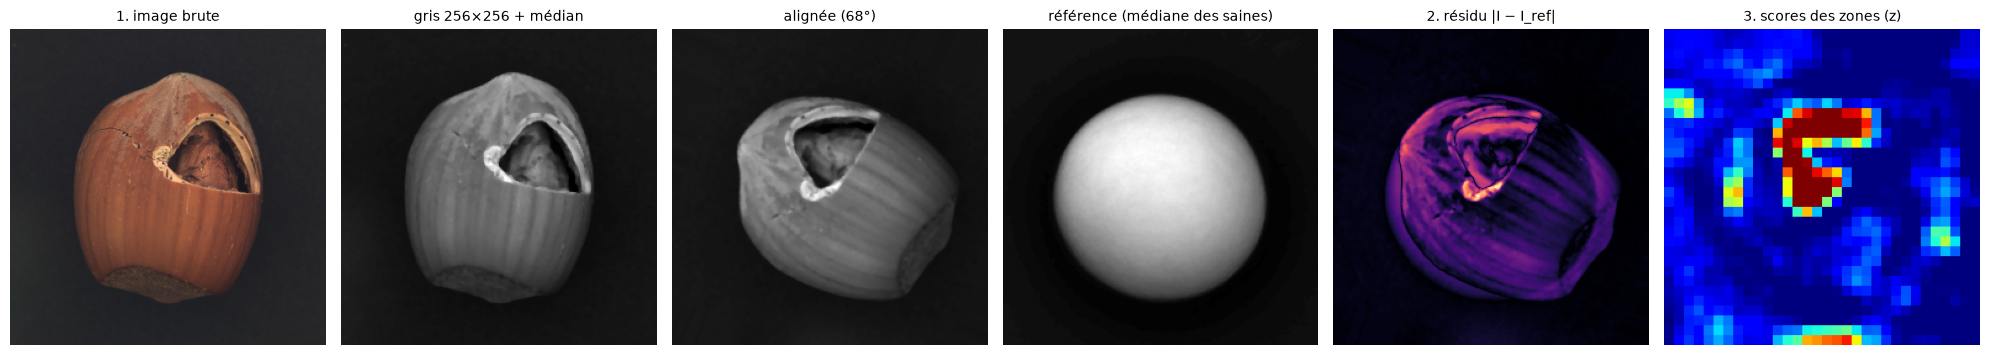

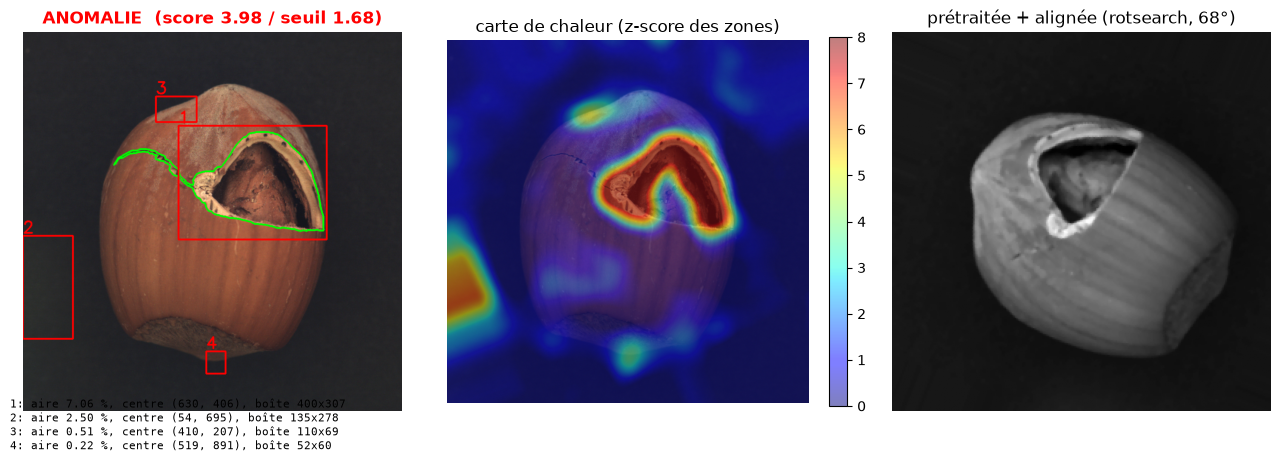

{'catégorie': 'hazelnut', 'décision': 'ANOMALIE', 'score': 3.981, 'seuil': 1.677, 'nb régions': 4, 'surface défaut %': 10.28, 'temps (ms)': 3573.3}


In [2]:
c = "hazelnut"; x = next(s for s in TEST[c] if s.defect == "crack")
insp = INSP[c]; pre = insp.det.pre; fx = insp.det.fx
raw = load_image(x.path)
g = to_gray_resized(raw, pre.size); d = denoise(g, pre.denoise_method, pre.ksize); n = normalize_photometric(d, pre.normalize)
pred = insp.predict(x.path)
resid = np.abs(pred.aligned.astype(float) - pre.reference.astype(float))
zmap = zones_to_pixels(insp.det.zone_model.score(fx.zones(pred.aligned)[None])[0], pre.size, fx.zone, fx.stride)
steps = [("1. image brute", cv2.cvtColor(raw, cv2.COLOR_BGR2RGB), None), ("gris 256×256 + médian", d, "gray"),
         (f"alignée ({pred.align_info.angle:.0f}°)", pred.aligned, "gray"), ("référence (médiane des saines)", pre.reference, "gray"),
         ("2. résidu |I − I_ref|", resid, "magma"), ("3. scores des zones (z)", np.clip(zmap, 0, 8), "jet")]
fig, axes = plt.subplots(1, 6, figsize=(20, 3.6))
for ax, (t, im, cm) in zip(axes, steps):
    ax.imshow(im, cmap=cm); ax.set_title(t, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()
render(pred, gt_mask=load_mask(x), show=True); print(pred.summary())

## 2. Exemples de décisions sur les 3 catégories
Contour **vert** = vérité terrain, boîtes **rouges** = régions signalées par le détecteur.

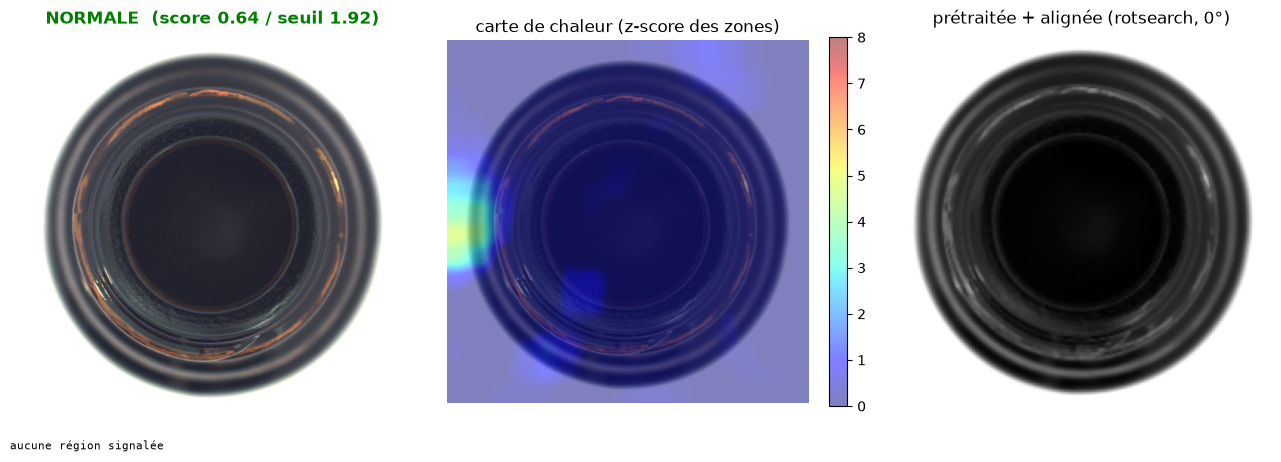

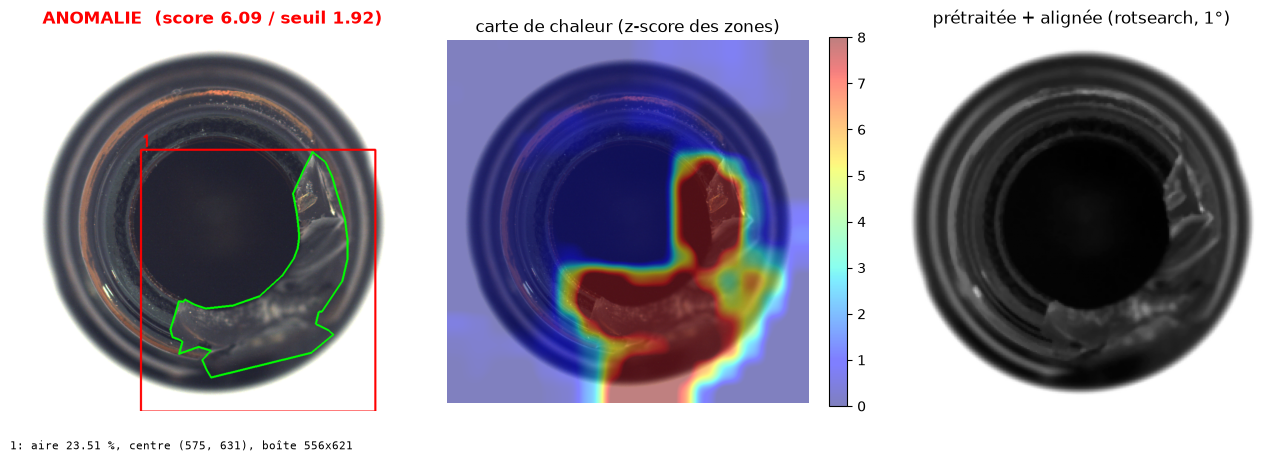

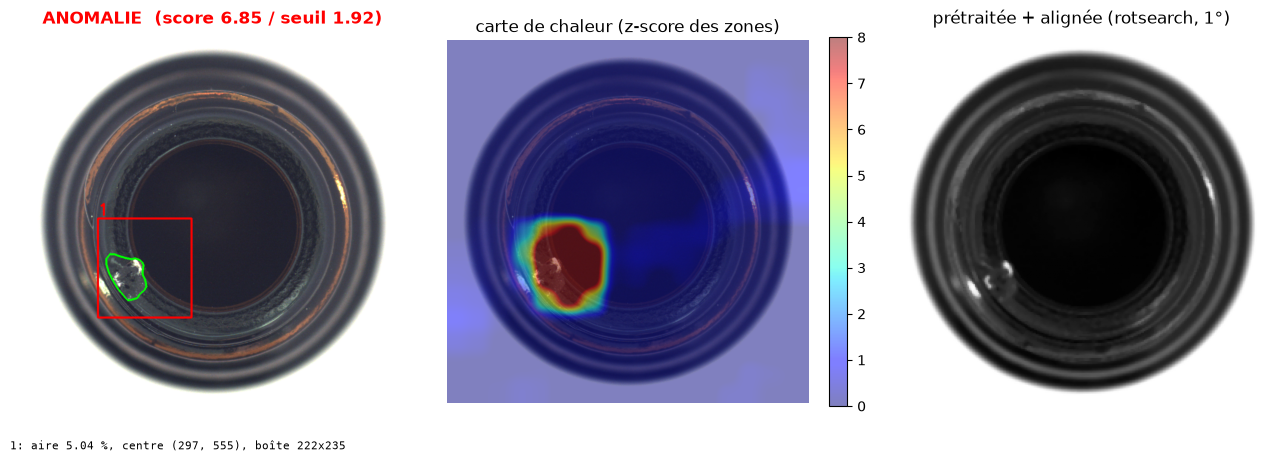

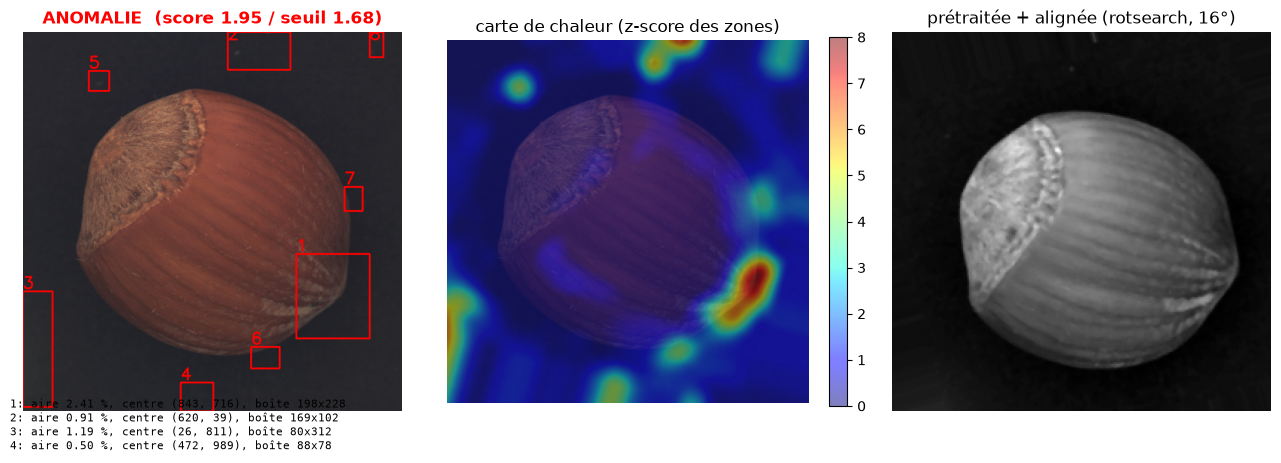

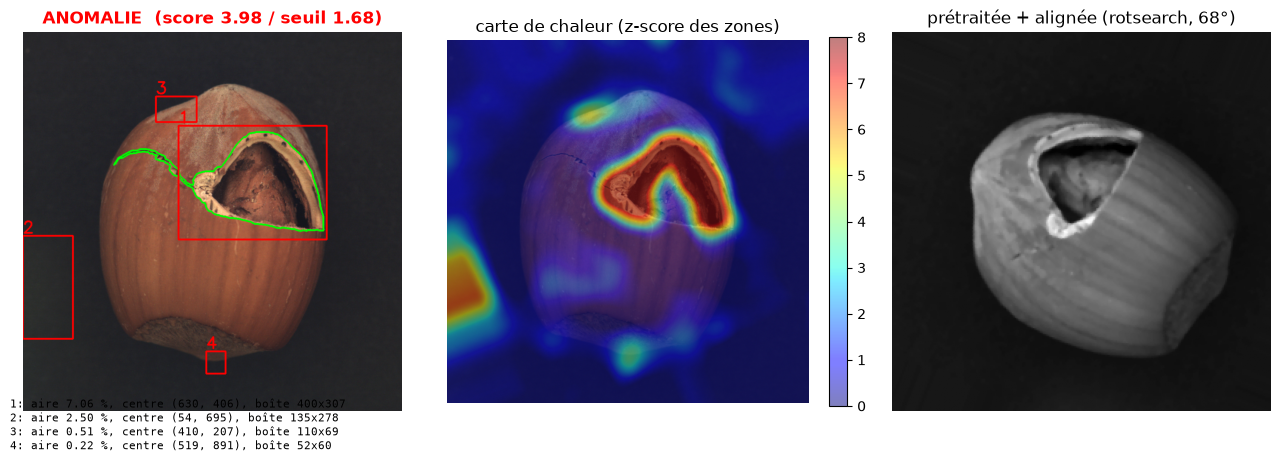

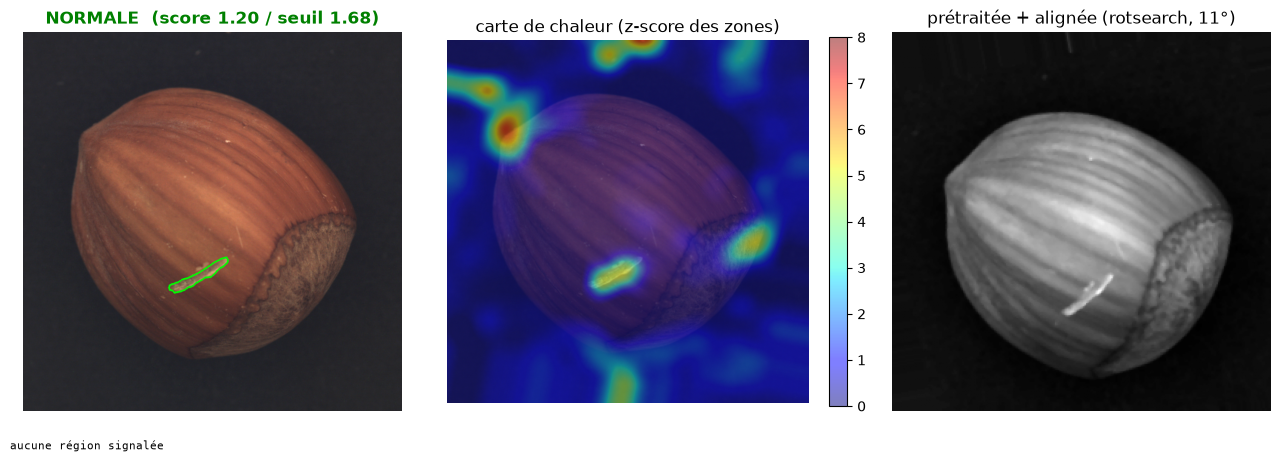

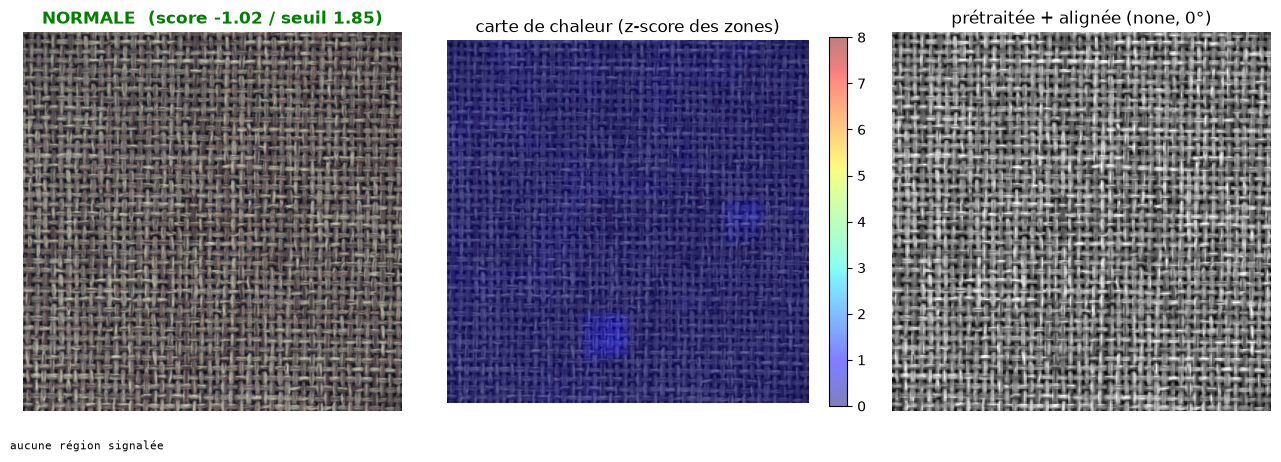

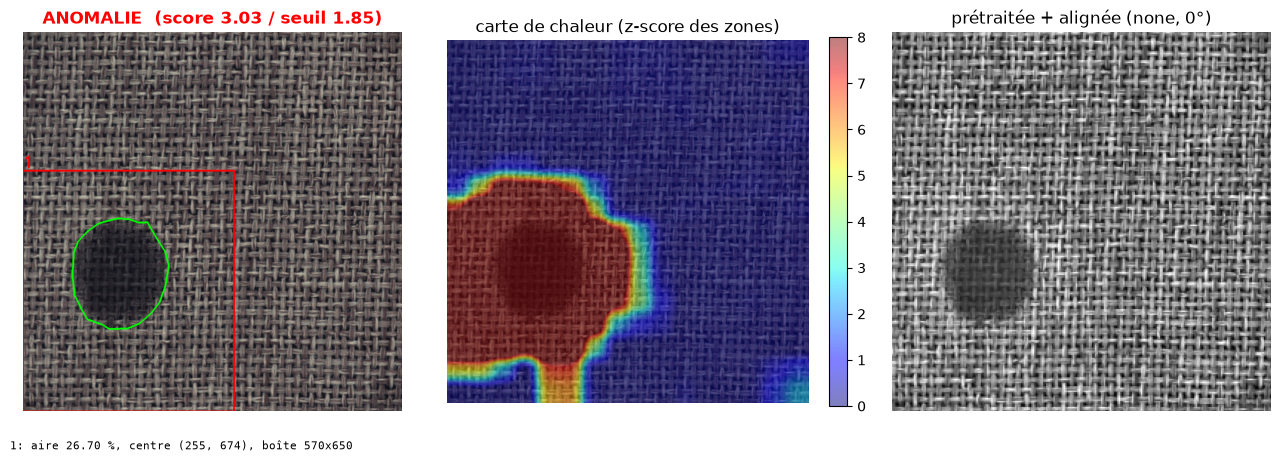

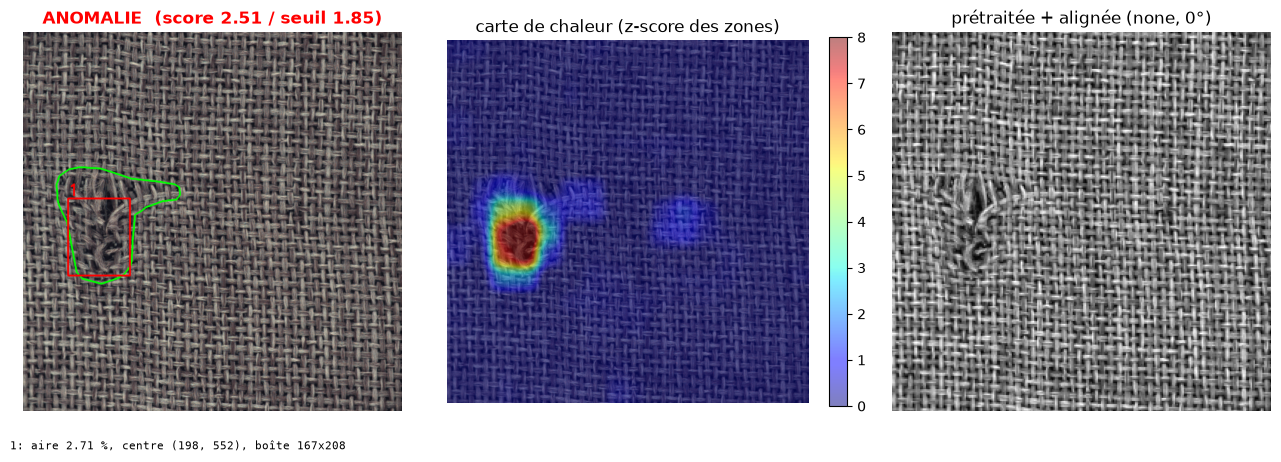

In [3]:
for c in CATS:
    test = TEST[c]
    picks = [next(s for s in test if s.label == 0)] + [next(s for s in test if s.defect == d) for d in sorted({s.defect for s in test if s.label})[:2]]
    for s in picks:
        render(INSP[c].predict(s.path), gt_mask=load_mask(s) if s.label else None, show=True)

## 3. Résultats sur le test (aucun vrai défaut utilisé pour entraîner, choisir ou fixer le seuil)

In [4]:
E = ROOT / "results" / "06_evaluation"
img = pd.read_csv(E / "tableau_image.csv", index_col=0)[["défauts détectés", "sains rejetés", "AUROC", "AP", "F1", "rappel @10% FA"]]
pix = pd.read_csv(E / "tableau_pixel.csv", index_col=0)[["AUROC pixel"]]
img.join(pix)

,défauts détectés,sains rejetés,AUROC,AP,F1,rappel @10% FA,AUROC pixel
bottle,61/63,3/20,0.990,0.997,0.961,0.968,0.954
hazelnut,51/70,6/40,0.846,0.914,0.803,0.714,0.886
carpet,35/89,1/28,0.779,0.923,0.560,0.528,0.771


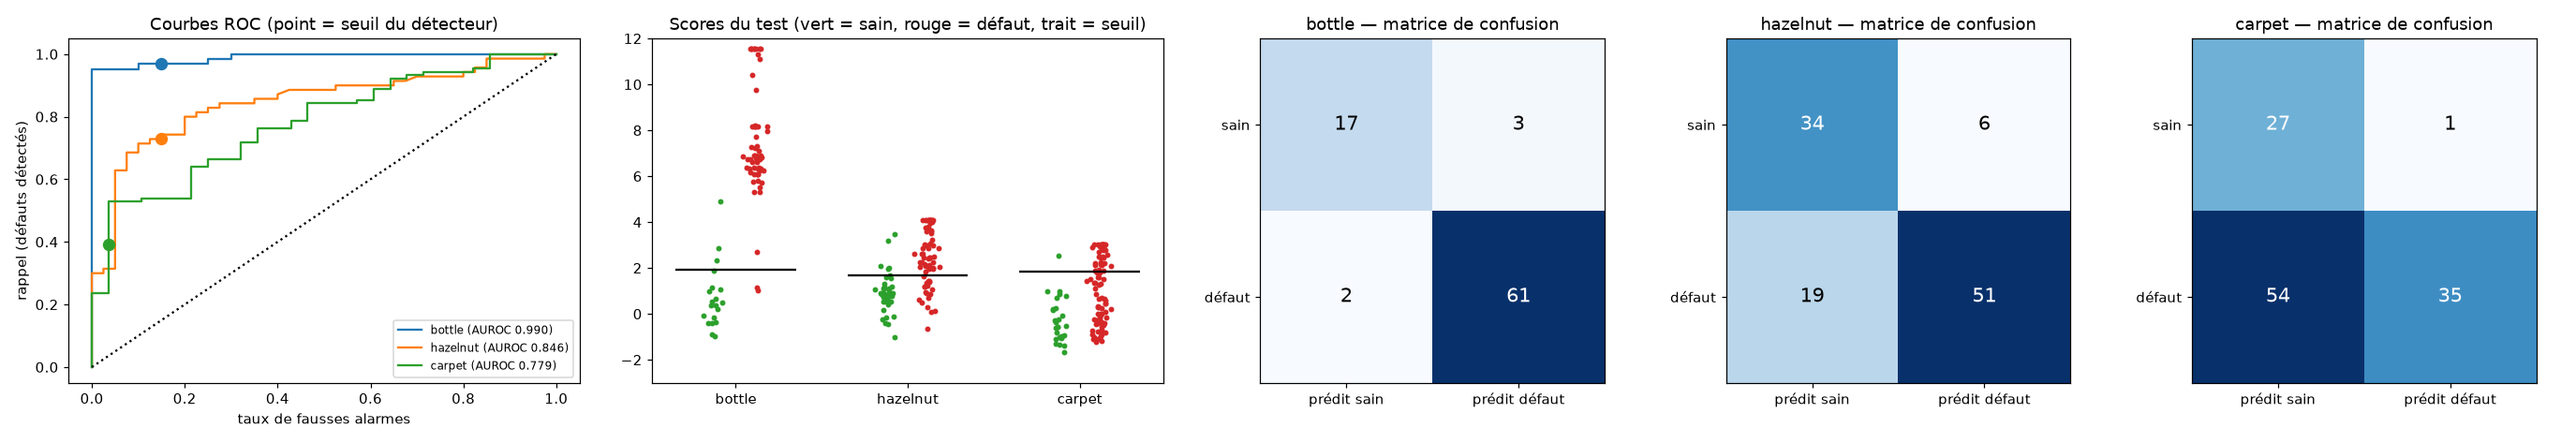

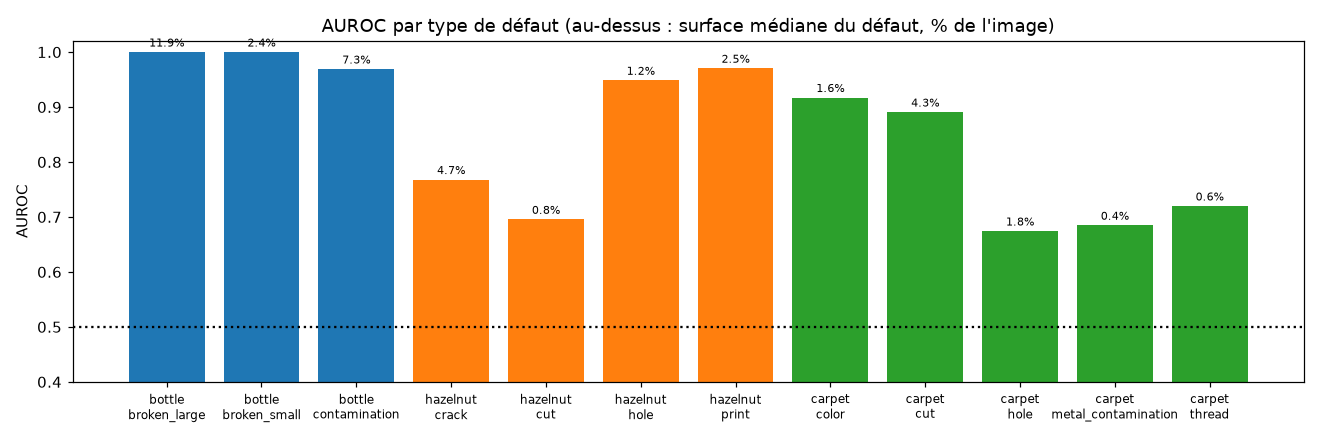

In [5]:
display(Image(filename=str(E / "roc_scores_confusion.png")))
display(Image(filename=str(E / "auroc_par_defaut.png")))

## 4. Étude d'ablation : que rapporte chaque élément du cours ?
On retire **un seul élément à la fois** (Δ AUROC par rapport au pipeline de référence de l'étape 6).

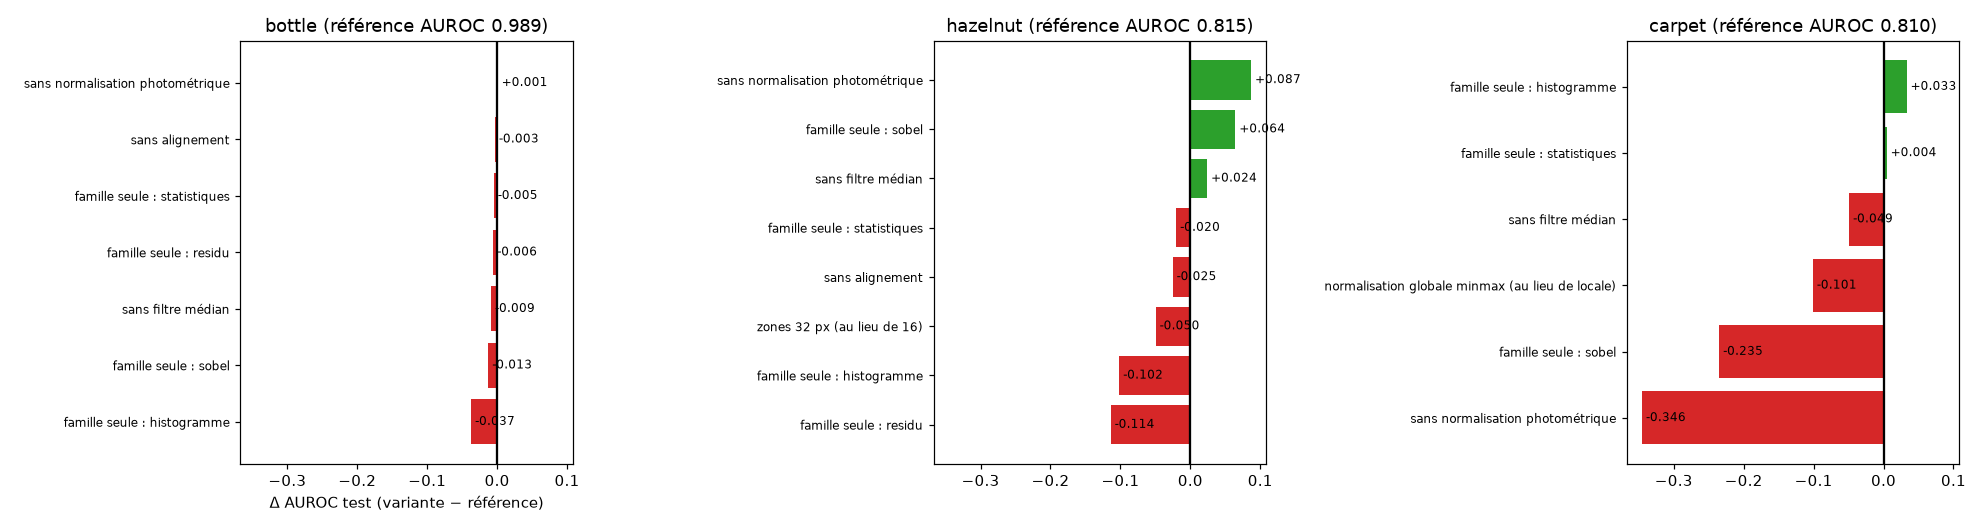

In [6]:
display(Image(filename=str(E / "ablation.png")))

## 5. À retenir

**Ce qui fonctionne**
- **bottle**, objet bien aligné : AUROC **0,99**, F1 **0,96**. La comparaison zone par zone avec une image de référence (soustraction d'images, Ch. 2) est très efficace.
- **Localisation** : la région la plus anormale tombe sur le vrai défaut dans 80 à 100 % des cas.
- Les défauts **grands ou contrastés** sont détectés avec une AUROC de 0,92 à 1,00.

**Ce que le projet montre sur les méthodes du cours**
- **ORB + RANSAC** recale parfaitement une même image tournée, mais **pas deux objets différents** (0 à 21 % de réussite). L'alignement passe donc par le centroïde de la région (Ch. 3) et une recherche de rotation (Ch. 2).
- Les **histogrammes par zone** battent les descripteurs **ORB/SIFT globaux** pour cette tâche.
- La **normalisation locale de l'éclairage** (filtre passe-bas) est indispensable pour la texture : sans elle, l'AUROC de carpet passe de 0,81 à 0,47.
- Le **filtre médian** est le meilleur filtre contre le bruit impulsionnel. Son effet est faible sur MVTec, qui est peu bruité.

**Méthode** : aucun vrai défaut n'est utilisé pour entraîner ni pour choisir. Le choix se fait par **anomalies synthétiques**, et le seuil par **validation croisée** sur les images saines.

**Limites** : défauts de moins de 1 % de l'image (AUROC de 0,67 à 0,72) ; produits naturels de forme variable ; 15 % de fausses alarmes sur bottle et hazelnut (cible 5 %, mesurée sur peu d'images) ; critère synthétique peu fiable pour hazelnut et carpet ; localisation grossière. Ce sont les limites d'une approche **classique** (caractéristiques manuelles et modèles à une classe).